# Streaming

In [ ]:
import os
import pyrealsense2 as rs
import numpy as np
import cv2

In [ ]:
# config classes
pipeline = rs.pipeline()
config = rs.config()

# Get device product line for setting a supporting resolution
pipeline_wrapper = rs.pipeline_wrapper(pipeline)
pipeline_profile = config.resolve(pipeline_wrapper)

device = pipeline_profile.get_device()
device_product_line = str(device.get_info(rs.camera_info.product_line))

found_rgb = False
for s in device.sensors:
    if s.get_info(rs.camera_info.name) == "RGB Camera":
        found_rgb = True
        break
if not found_rgb:
    print("The demo requires Depth camera with Color sensor")
    exit(0)


In [ ]:
# depth
config.enable_stream(
    stream_type=rs.stream.depth, width=640, height=480, format=rs.format.z16, framerate=60
)
# color
config.enable_stream(
    stream_type=rs.stream.color, width=640, height=480, format=rs.format.bgr8, framerate=60
)
# infra
# config.enable_stream(
#     stream_type=rs.stream.infrared, width=640, height=480, format=rs.format.bgr8 , framerate=60
# )

# is selected config (for specific pipeline) valid
if config.can_resolve(pipeline):
    print('config OK')
else:
    print('baj van')

In [ ]:
# Start streaming
pipeline.start(config)

try:
    while True:

        # Wait for a coherent pair of frames: depth and color
        frames = pipeline.wait_for_frames()
        depth_frame = frames.get_depth_frame()
        color_frame = frames.get_color_frame()
        # infra_frame = frames.get_infrared_frame()

        if not depth_frame or not color_frame:
            continue

        # Convert images to numpy arrays
        depth_image = np.asanyarray(depth_frame.get_data())
        color_image = np.asanyarray(color_frame.get_data())
        # infra_image = np.asanyarray(infra_frame.get_data())

        # Apply colormap on depth image (image must be converted to 8-bit per pixel first)
        depth_colormap = cv2.applyColorMap(
            cv2.convertScaleAbs(depth_image, alpha=0.03), cv2.COLORMAP_JET
        )

        depth_colormap_dim = depth_colormap.shape
        color_colormap_dim = color_image.shape

        # If depth and color resolutions are different, resize color image to match depth image for display
        if depth_colormap_dim != color_colormap_dim:
            resized_color_image = cv2.resize(
                color_image,
                dsize=(depth_colormap_dim[1], depth_colormap_dim[0]),
                interpolation=cv2.INTER_AREA,
            )
            images = np.hstack((resized_color_image, depth_colormap))
        else:
            images = np.hstack((color_image, depth_colormap))
            # images = np.hstack((color_image, depth_colormap, infra_image))

        # Show images
        cv2.namedWindow("RealSense", cv2.WINDOW_AUTOSIZE)
        cv2.imshow("RealSense", images)

        # press q to exit without crash
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break
    cv2.destroyAllWindows()

finally:

    # Stop streaming
    pipeline.stop()


In [ ]:
infra_image.shape, color_image.shape, depth_image.shape

In [ ]:
ord('e')

# Recording

In [ ]:
import os
import time
import pyrealsense2 as rs
import numpy as np
import cv2
import logging
import time

In [ ]:
# set recording name & parameters
recording_name = "asdf"
recording_file_name = os.path.join("data", recording_name, recording_name + ".db3")
WIDTH = 848
HEIGHT = 480
FPS = 60
DURATION = 5  # seconds

if not os.path.isdir(os.path.join("data", recording_name)):
    os.mkdir(os.path.join("data", recording_name))

# config classes
pipeline = rs.pipeline()
config = rs.config()

# depth
config.enable_stream(
    stream_type=rs.stream.depth, width=WIDTH, height=HEIGHT, format=rs.format.z16, framerate=FPS
)
# color
config.enable_stream(
    stream_type=rs.stream.color, width=WIDTH, height=HEIGHT, format=rs.format.bgr8, framerate=FPS
)
# enable recording
config.enable_record_to_file(file_name=recording_file_name)
queue = rs.frame_queue(capacity=200, keep_frames=True)

# is selected config (for specific pipeline) valid
if config.can_resolve(pipeline):
    print("config OK")
else:
    print("baj van")

In [ ]:
pipeline.start(config, queue)

start_time = time.time()
current_time = 0

try:
    while current_time - start_time < DURATION:

        frames = queue.wait_for_frame()
        frames = frames.as_frameset()

        depth_frame = frames.get_depth_frame()
        color_frame = frames.get_color_frame()
        # infra_frame = frames.get_infrared_frame()

        if not depth_frame or not color_frame:
            continue

        depth_image = np.asanyarray(depth_frame.get_data())
        color_image = np.asanyarray(color_frame.get_data())
        # infra_image = np.asanyarray(infra_frame.get_data())

        # Apply colormap on depth image (image must be converted to 8-bit per pixel first)
        depth_colormap = cv2.applyColorMap(
            cv2.convertScaleAbs(depth_image, alpha=0.03), cv2.COLORMAP_JET
        )

        depth_colormap_dim = depth_colormap.shape
        color_colormap_dim = color_image.shape

        # If depth and color resolutions are different, resize color image to match depth image for display
        if depth_colormap_dim != color_colormap_dim:
            resized_color_image = cv2.resize(
                color_image,
                dsize=(depth_colormap_dim[1], depth_colormap_dim[0]),
                interpolation=cv2.INTER_AREA,
            )
            images = np.hstack((resized_color_image, depth_colormap))
        else:
            images = np.hstack((color_image, depth_colormap))

        current_time = time.time()

        cv2.namedWindow("RealSense", cv2.WINDOW_AUTOSIZE)
        cv2.imshow("RealSense", images)

        # press q to exit without crash
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break
    cv2.destroyAllWindows()

finally:
    pipeline.stop()

# Playback from file

In [ ]:
import pyrealsense2 as rs
import numpy as np
import cv2
import os

In [ ]:
recording_name = "t1"
recording_file_name = os.path.join("data", recording_name, recording_name + ".db3")
if not os.path.exists(recording_file_name):
    raise FileNotFoundError(f'File {recording_file_name} does not exits')

pipeline = rs.pipeline()
config = rs.config()

config.enable_device_from_file(file_name=recording_file_name, repeat_playback=False)

config.enable_stream(
    stream_type=rs.stream.depth, width=848, height=480, format=rs.format.z16, framerate=60
)
config.enable_stream(
    stream_type=rs.stream.color, width=848, height=480, format=rs.format.bgr8, framerate=60
)
if config.can_resolve(pipeline):
    print('config OK')

In [ ]:
# Start streaming from file
pipeline.start(config)


# Create colorizer object
colorizer = rs.colorizer()
frames = None

success = True
frame_meta = []

while success:

    success, frames = pipeline.try_wait_for_frames(timeout_ms=500)

    if frames:

        depth_frame = frames.get_depth_frame()
        # Colorize depth frame to jet colormap
        depth_color_frame = colorizer.colorize(depth_frame)
        # Convert depth_frame to numpy array to render image in opencv
        depth_color_image = np.asanyarray(depth_color_frame.get_data())

        color_frame = frames.get_color_frame()
        color_image = np.asanyarray(color_frame.get_data())

        images = np.hstack((color_image, depth_color_image))

        cv2.imshow("Playback", images)
    key = cv2.waitKey(1)
    # if pressed escape exit program
    if key == 27 or key == ord("q"):
        cv2.destroyAllWindows()
        break
    
cv2.destroyAllWindows()
pipeline.stop()

# Align, save color & depth

.db3 --> .mp4 (color), .raw (depth), .bin (timestamps), .json (metadata)

In [1]:
import os
import json
import subprocess
import numpy as np
import pyrealsense2 as rs
import glob
from util import create_ffmpeg_command
%matplotlib ipympl

recording_name = "t1"
out_folder = os.path.join("data", recording_name)

if os.path.isdir(out_folder):
    recording_file_name = os.path.join(out_folder, recording_name + ".db3")
    if not os.path.exists(recording_file_name):
        raise FileNotFoundError(f'File {recording_file_name} does not exist')
    out_filename_color = os.path.join(out_folder,recording_name+"_color.mp4")
    out_filename_depth = os.path.join(out_folder, recording_name+"_depth.mkv")
    out_filename_timestamps = os.path.join(out_folder, recording_name+"_timestamps.bin")
    out_filename_metadata = os.path.join(out_folder, recording_name+"_metadata.json")
else:
    raise FileNotFoundError(f"Folder {recording_name} does not exist")

In [2]:
# config
pipeline = rs.pipeline()
config = rs.config()
config.enable_device_from_file(recording_file_name, repeat_playback=False)

profile = pipeline.start(config)

# Get depth intrinsics
depth_profile = profile.get_stream(rs.stream.depth)
depth_intrinsics = depth_profile.as_video_stream_profile().get_intrinsics()

# Get color intrinsics
color_profile = profile.get_stream(rs.stream.color)
color_intrinsics = color_profile.as_video_stream_profile().get_intrinsics()

playback = profile.get_device().as_playback()
playback.set_real_time(False)

# align_to=rs.stream.color/infra... -> aligns depth to other
# align_to=RS2_STREAM_DEPTH -> align other stream to depth
align = rs.align(align_to=rs.stream.color)

depth_sensor = profile.get_device().first_depth_sensor()
depth_scale = depth_sensor.get_depth_scale()

# filters
threshold = rs.threshold_filter(min_dist=0.05, max_dist=10.0)
depth_to_disparity = rs.disparity_transform(True)
spatial = rs.spatial_filter()
spatial.set_option(rs.option.filter_magnitude, 2)
spatial.set_option(rs.option.filter_smooth_alpha, 0.5)
spatial.set_option(rs.option.filter_smooth_delta, 20)
temporal = rs.temporal_filter()
disparity_to_depth = rs.disparity_transform(False)

ffmpeg_color = create_ffmpeg_command(
    width=color_intrinsics.width,
    height=color_intrinsics.height,
    fps=color_profile.fps(),
    encoder="h264_qsv",
    out_filename=out_filename_color,
)
video_color = subprocess.Popen(ffmpeg_color, stdin=subprocess.PIPE)

ffmpeg_depth = [
            "ffmpeg", "-y",
            "-f", "rawvideo", "-pix_fmt", "gray16le",
            "-s", f"{color_intrinsics.width}x{color_intrinsics.height}",
            "-r", str(color_profile.fps()),
            "-i", "-",
            "-c:v", "ffv1",
            out_filename_depth,
        ]
video_depth = subprocess.Popen(ffmpeg_depth, stdin=subprocess.PIPE)


# output files
# depth_out = open(out_filename_depth, "wb", buffering=16 * 1024 * 1024)
timestamps_out = open(out_filename_timestamps, "wb", buffering=1024 * 1024)

frame_count = 0

print(f"Input:  {recording_file_name}\n")
print("Converting...")

try:
    while True:
        try:
            frames = pipeline.wait_for_frames()
        except RuntimeError:
            break

        # Align depth to the color camera
        # NOTE: later only the color intrinsics are needed
        aligned_frames = align.process(frames)
        color_frame = aligned_frames.get_color_frame()
        depth_frame = aligned_frames.get_depth_frame()

        if not color_frame or not depth_frame:
            continue

        color_image = np.asanyarray(color_frame.get_data())
        # depth_image = np.asanyarray(depth.get_data())

        filtered = threshold.process(depth_frame)
        filtered = depth_to_disparity.process(filtered)
        filtered = spatial.process(filtered)
        # filtered = temporal.process(filtered)
        filtered = disparity_to_depth.process(filtered)
        filtered = filtered.as_depth_frame()
        depth_image = np.asanyarray(filtered.get_data())

        video_color.stdin.write(color_image.tobytes())
        video_depth.stdin.write(depth_image.tobytes())
        # depth_out.write(depth_image.tobytes())
        # TODO: maybe write the ts of both frames?
        timestamp = frames.get_timestamp()

        timestamps_out.write(np.float64(timestamp).tobytes())

        frame_count += 1

        if frame_count % 60 == 0:
            print(f"\rFrames: {frame_count}", end="", flush=True)

finally:

    video_color.stdin.close()
    video_color.wait()

    video_depth.stdin.close()
    video_depth.wait()

    # depth_out.close()
    timestamps_out.close()
    try:
        pipeline.stop()
    except Exception as e:
        f"pipeline.stop() raised: {type(e).__name__}: {e}"

metadata = {
    "frames": frame_count,
    "width": color_intrinsics.width,
    "height": color_intrinsics.height,
    "fps": color_profile.fps(),
    "color": out_filename_color,
    "depth": out_filename_depth,
    "depth_format": "uint16",
    "depth_alignment": "depth_to_color",
    "depth_scale_meters": depth_scale,
    "timestamps": out_filename_timestamps,
    "timestamp_unit": "milliseconds",
    "depth_intrinsics": {
        "width": depth_intrinsics.width,
        "height": depth_intrinsics.height,
        "ppx": depth_intrinsics.ppx,
        "ppy": depth_intrinsics.ppy,
        "fx": depth_intrinsics.fx,
        "fy": depth_intrinsics.fy,
        "model": str(depth_intrinsics.model),
        "coeffs": depth_intrinsics.coeffs,
    },
    "color_intrinsics": {
        "width": color_intrinsics.width,
        "height": color_intrinsics.height,
        "ppx": color_intrinsics.ppx,
        "ppy": color_intrinsics.ppy,
        "fx": color_intrinsics.fx,
        "fy": color_intrinsics.fy,
        "model": str(color_intrinsics.model),
        "coeffs": color_intrinsics.coeffs,
    },
}

with open(out_filename_metadata, "w") as f:
    json.dump(metadata, f, indent=2)

print("\n\nDone.")
print(f"Frames: {frame_count}")
print(f"Color:  {out_filename_color}")
print(f"Depth:  {out_filename_depth}")
print(f"Timestamps:  {out_filename_timestamps}")
print(f"Metadata:  {out_filename_metadata}")

Input:  data\t1\t1.db3

Converting...
Frames: 3840

Done.
Frames: 3860
Color:  data\t1\t1_color.mp4
Depth:  data\t1\t1_depth.mkv
Timestamps:  data\t1\t1_timestamps.bin
Metadata:  data\t1\t1_metadata.json


In [5]:
str(color_profile.fps())

'60'

In [ ]:
# import pyrealsense2 as rs
# import numpy as np

# recording_file_name = "data/asdf/asdf.db3"
# filtered_depth_output_path = "data/asdf/asdf_depth_filtered.raw"

# pipeline = rs.pipeline()
# config = rs.config()
# config.enable_device_from_file(recording_file_name, repeat_playback=False)
# profile = pipeline.start(config)
# profile.get_device().as_playback().set_real_time(False)

# align = rs.align(rs.stream.color)

# threshold = rs.threshold_filter(min_dist=0.3, max_dist=6.0)
# depth_to_disparity = rs.disparity_transform(True)
# spatial = rs.spatial_filter()
# spatial.set_option(rs.option.filter_magnitude, 2)
# spatial.set_option(rs.option.filter_smooth_alpha, 0.5)
# spatial.set_option(rs.option.filter_smooth_delta, 20)
# temporal = rs.temporal_filter()
# disparity_to_depth = rs.disparity_transform(False)

# depth_frames_out = []
# width = height = None

# while True:
#     try:
#         frames = pipeline.wait_for_frames()
#     except RuntimeError:
#         break  # end of file

#     aligned = align.process(frames)
#     depth_frame = aligned.get_depth_frame()
#     color_frame = aligned.get_color_frame()
#     if not depth_frame or not color_frame:
#         continue

#     # filter only the depth frame — color is untouched, not even referenced below
#     filtered = threshold.process(depth_frame)
#     filtered = depth_to_disparity.process(filtered)
#     filtered = spatial.process(filtered)
#     filtered = temporal.process(filtered)
#     filtered = disparity_to_depth.process(filtered)
#     filtered = filtered.as_depth_frame()

#     if width is None:
#         width = filtered.get_width()
#         height = filtered.get_height()

#     depth_image = np.asanyarray(filtered.get_data())
#     depth_frames_out.append(depth_image.copy())

# pipeline.stop()

# depth_stack = np.stack(depth_frames_out).astype(np.uint16)
# depth_stack.tofile(filtered_depth_output_path)

# print(f"Wrote {depth_stack.shape[0]} frames of shape {(height, width)} to {filtered_depth_output_path}")

# Get 2D keypoints

mp4 --> 2D keypoints (camera frame)

In [7]:
import os
import sys
import cv2
import time
import importlib
import numpy as np
from util import Custom
from pathlib import Path
import onnxruntime as ort
from IPython.display import display, clear_output
rtmlib_module = importlib.import_module("rtmlib")

device = 'cuda'
backend = 'onnxruntime'
openpose_skeleton = False

site_packages = Path(sys.prefix) / "Lib" / "site-packages"
cuda_bin = site_packages / "nvidia" / "cu13" / "bin" / "x86_64"
cudnn_bin = site_packages / "nvidia" / "cudnn" / "bin"

os.add_dll_directory(str(cuda_bin))
os.add_dll_directory(str(cudnn_bin))
ort.preload_dlls(
    cuda=True,
    cudnn=True,
    directory=str(cuda_bin),
)

print("ORT providers:", ort.get_available_providers())
# custom = Custom(
#     det_class="YOLOX",  #'RTMDet',
#     det="https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/onnx_sdk/yolox_nano_8xb8-300e_humanart-40f6f0d0.zip",
#     det_input_size=(416,416),
#     pose_class="RTMPose",
#     pose='https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/onnx_sdk/rtmpose-x_simcc-body7_pt-body7-halpe26_700e-384x288-7fb6e239_20230606.zip',
#     pose_input_size=(288,384),
#     backend=backend,
#     device=device,
# )

custom = Custom(
    det_class="YOLOX",  #'RTMDet',
    det="https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/onnx_sdk/yolox_nano_8xb8-300e_humanart-40f6f0d0.zip",
    det_input_size=(416,416),
    pose_class="RTMPose",
    pose="https://download.openmmlab.com/mmpose/v1/projects/rtmposev1/onnx_sdk/rtmpose-m_simcc-body7_pt-body7-halpe26_700e-256x192-4d3e73dd_20230605.zip",
    pose_input_size=(192, 256),
    backend=backend,
    device=device,
)

ORT providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
load C:\Users\unger\.cache\rtmlib\hub\checkpoints\yolox_nano_8xb8-300e_humanart-40f6f0d0.onnx with onnxruntime backend
load C:\Users\unger\.cache\rtmlib\hub\checkpoints\rtmpose-m_simcc-body7_pt-body7-halpe26_700e-256x192-4d3e73dd_20230605.onnx with onnxruntime backend


In [ ]:
recording_name = "t1"
input_video_filename = os.path.join("data", recording_name, recording_name+"_color.mp4")
out_filename_keypoints_2d = os.path.join("data", recording_name, recording_name+"_keypoints_2d")
if not os.path.exists(input_video_filename):
    raise FileNotFoundError(f'File {input_video_filename} does not exist')

print(f"processing: {input_video_filename}")

# containers to store the results in
keypoints_2d = []
mid_shoulder = []

cap = cv2.VideoCapture(input_video_filename)
if cap.isOpened() == False:
    raise FileNotFoundError(f"Error opening video file: {input_video_filename}")

total_num_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
processed_num_frames = 0
start_time = time.time_ns()

while cap.isOpened():
    ret, frame = cap.read()

    if ret == True:
        processed_num_frames += 1

        frame = cv2.rotate(frame, cv2.ROTATE_90_COUNTERCLOCKWISE)
        # frame = cv2.resize(frame, (192, 256))

        width = frame.shape[1]
        height = frame.shape[0]

        # inference
        keypoints, scores = custom(frame)

        # visualize
        # boxes = [pose_to_bbox(x) for x in keypoints]
        # img_show = draw_bbox(frame, boxes, (0, 0, 255))

        # store results (frames * kpt * (x,y)), remove multiperson cases
        if keypoints.shape != (1, 26, 2):
            keypoints = keypoints[0, :, :]
            scores = scores[0, :]

        keypoints = np.squeeze(keypoints)

        keypoints_2d.append(keypoints)

        for kpt in keypoints[:, :]:
            cv2.circle(frame, (int(kpt[0]), int(kpt[1])), 3, (0, 255, 0), 2)

        cv2.imshow("Image", cv2.resize(frame, (int(width), int(height))))

        # display how much time elapsed/is left
        clear_output(wait=True)
        end_time = time.time_ns()
        elapsed_time = (end_time - start_time) / 1000000000

        fps = round(processed_num_frames / elapsed_time, 2)
        done_ratio = processed_num_frames / total_num_frames
        expected_duration_min = elapsed_time / (done_ratio * 60)

        display(
            f"exp_duration: {round(expected_duration_min,2)} minutes, elapsed: {round(elapsed_time/60,2)} minutes"
        )
        display(f"done: {round(done_ratio*100,2)}%, fps: {fps}")

        # Press Q on keyboard to exit
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break
    else:
        break
cap.release()
cv2.destroyAllWindows()

keypoints_2d = np.asarray(keypoints_2d)
# mid_shoulder = np.expand_dims(np.array(mid_shoulder), axis=1)
# keypoints_2d = np.hstack((keypoints_2d, mid_shoulder))
np.save(out_filename_keypoints_2d, keypoints_2d)

print(f"shape of keypoints_2d:  {keypoints_2d.shape} (frames * kpt * (x, y))")

'exp_duration: 2.7 minutes, elapsed: 0.26 minutes'

'done: 9.79%, fps: 23.79'

shape of keypoints_2d:  (378, 26, 2) (frames * kpt * (x, y))


# Get 3D keypoints

In [3]:
import os
import json
import numpy as np
import pyrealsense2 as rs
from util import create_intrinsics_object, sample_depth_patch

recording_name = "t1"
folder_name = os.path.join("data", recording_name)
filename_keypoints_2d = os.path.join(folder_name, recording_name+"_keypoints_2d.npy")
filename_metadata = os.path.join(folder_name, recording_name+"_metadata.json")
filename_depth = os.path.join(folder_name, recording_name+"_depth.raw")
out_filename_keypoints_3d = os.path.join(folder_name, recording_name+"_keypoints_3d.npy")

if not os.path.exists(filename_keypoints_2d):
    raise FileNotFoundError(f'File {filename_keypoints_2d} does not exist')
if not os.path.exists(filename_metadata):
    raise FileNotFoundError(f'File {filename_metadata} does not exist')
if not os.path.exists(filename_depth):
    raise FileNotFoundError(f'File {filename_depth} does not exist')

keypoints_2d = np.load(filename_keypoints_2d)
with open(filename_metadata) as f:
    metadata = json.load(f)

print(f'keypoints_2d: {keypoints_2d.shape}')
print(f'metadata loaded: {filename_metadata}')

keypoints_2d: (3860, 26, 2)
metadata loaded: data\t1\t1_metadata.json


In [4]:
keypoints_3d = []

depth_scale = metadata['depth_scale_meters']  # conversion to meters
intrinsics = create_intrinsics_object(intrinsics_dict=metadata['color_intrinsics'])

W = intrinsics.width
H = intrinsics.height

# raw (landscape) intrinsics — matches the raw depth file and raw (u,v), no rotation needed

bytes_per_frame = W * H * 2  # uint16 = 2 bytes/pixel

with open(filename_depth, "rb") as f:

    for frame_idx in range(metadata['frames']):
        current_keypoints_2d = keypoints_2d[frame_idx, :, :]

        f.seek(frame_idx * bytes_per_frame)
        current_frame_depth_map = np.fromfile(f, dtype=np.uint16, count=W * H).reshape(
            H, W
        )

        current_keypoints_3d = []
        for kpt_idx, (x_portrait, y_portrait) in enumerate(current_keypoints_2d):
            x_landscape = int(round(W - 1 - y_portrait))
            y_landscape = int(round(x_portrait))

            if not (0 <= x_landscape < W and 0 <= y_landscape < H):
                current_keypoints_3d.append([np.nan, np.nan, np.nan])
                continue

            # d = float(current_frame_depth_map[y_landscape, x_landscape]) * depth_scale
            d = sample_depth_patch(depth_map=current_frame_depth_map, x=y_landscape, y=x_landscape, radius=1) * depth_scale

            if d <= 0:  # invalid/missing depth reading
                current_keypoints_3d.append([np.nan, np.nan, np.nan])
                continue

            [x,y,d] = rs.rs2_deproject_pixel_to_point(
                intrin=intrinsics, pixel=(x_landscape, y_landscape), depth=d
            )
            current_keypoints_3d.append([d,y,x])

        keypoints_3d.append(current_keypoints_3d)

keypoints_3d = np.asanyarray(keypoints_3d)
np.save(out_filename_keypoints_3d, keypoints_3d)

# Transform 3D coords to global frame

## Calibration

In [18]:
import os
import numpy as np
from util import *

recording_name = "t1"
folder_name = os.path.join("data", recording_name)
filename_metadata = os.path.join(folder_name, recording_name+"_metadata.json")
filename_keypoints_3d = os.path.join(folder_name, recording_name+"_keypoints_3d.npy")
filename_calibration_img = os.path.join(folder_name, "calibration_image.png")
if not os.path.exists(filename_metadata):
    raise FileNotFoundError(f'File {filename_metadata} does not exist')
if not os.path.exists(filename_keypoints_3d):
    raise FileNotFoundError(f'File {filename_keypoints_3d} does not exist')
if not os.path.exists(filename_calibration_img):
    raise FileNotFoundError(f'File {filename_calibration_img} does not exist')

with open(filename_metadata) as f:
    metadata = json.load(f)

fx = metadata["color_intrinsics"]["fx"]
fy = metadata["color_intrinsics"]["fy"]
ppx = metadata["color_intrinsics"]["ppx"]
ppy = metadata["color_intrinsics"]["ppy"]

keypoints_3d = np.load(filename_keypoints_3d)
print(f'keypoints_3d: {keypoints_3d.shape}')

keypoints_3d: (3860, 26, 3)


In [ ]:
with open(filename_metadata) as f:
    metadata = json.load(f)

fx = metadata["color_intrinsics"]["fx"]
fy = metadata["color_intrinsics"]["fy"]
ppx = metadata["color_intrinsics"]["ppx"]
ppy = metadata["color_intrinsics"]["ppy"]


keypoints_3d_global_frame = []
for kpt in keypoints_3d.transpose(1,2,0):
    # camera-frame coordinates
    Xc = kpt[0, :]
    Yc = kpt[1, :]
    Zc = kpt[2, :]

    Xw = ((Xc - ppx) * Zc / fx) - translation_vector[0]
    Yw = -((Yc - ppy) * Zc / fy) - translation_vector[1]
    Zw = Zc - translation_vector[2]

    keypoints_3d_global_frame.append(np.array([Zw, Xw, Yw]))

# Camera -> world
points_world = (keypoints_3d_global_frame - translation_vector.reshape(1, 1, 3)) @ R
points_world = points_world/1000

keypoints_3d_global_frame = np.array(keypoints_3d_global_frame).transpose(2, 0, 1)

In [ ]:
with open("./t1_metadata.json") as f:
    metadata = json.load(f)
H, W = metadata['height'], metadata['width']

fx = metadata["color_intrinsics"]["fx"]
fy = metadata["color_intrinsics"]["fy"]
ppx = metadata["color_intrinsics"]["ppx"]
ppy = metadata["color_intrinsics"]["ppy"]

fx_rot  = fy
fy_rot  = fx
ppx_rot = H - 1 - ppy
ppy_rot = ppx

keypoints_3d_global_frame = []
for kpt in keypoints_3d.transpose(1,2,0):
    # camera-frame coordinates
    Xc = kpt[0, :]
    Yc = kpt[1, :]
    Zc = kpt[2, :]

    Xw = ((Xc - ppx_rot) * Zc / fx_rot)
    Yw = ((Yc - ppy_rot) * Zc / fy_rot)
    Zw = Zc

    keypoints_3d_global_frame.append(np.array([ Xw, Yw, Zw]))

keypoints_3d_global_frame = np.array(keypoints_3d_global_frame).transpose(2, 0, 1)
# Camera -> world
points_world = (keypoints_3d_global_frame - translation_vector.reshape(1, 1, 3)) @ R
points_world = points_world/1000


In [ ]:
pattern = Pattern(height=7, width=4, square_size=0.1)
with open("./t1_metadata.json") as f:
    metadata = json.load(f)
H, W = metadata['height'], metadata['width']

fx = metadata["color_intrinsics"]["fx"]
fy = metadata["color_intrinsics"]["fy"]
ppx = metadata["color_intrinsics"]["ppx"]
ppy = metadata["color_intrinsics"]["ppy"]

distortion_coeffs = metadata["color_intrinsics"]["coeffs"]
distortion_coeffs = np.array(distortion_coeffs)

calibration_image = cv2.imread('./calibration_image.png', cv2.IMREAD_GRAYSCALE)
calibration_image = cv2.rotate(calibration_image, cv2.ROTATE_90_COUNTERCLOCKWISE)

found, corners = cv2.findChessboardCorners(calibration_image, pattern.pattern_size)

fx_rot  = fy
fy_rot  = fx
ppx_rot = H - 1 - ppy
ppy_rot = ppx
K_rot = np.array([
    [fx_rot, 0, ppx_rot],
    [0, fy_rot, ppy_rot],
    [0, 0, 1]
], dtype=np.float64)


projected, _ = cv2.projectPoints(
    pattern.pattern_points,
    rvec,
    translation_vector,
    K_rot,
    distortion_coeffs
)
error = np.linalg.norm(
    projected.reshape(-1, 2) - corners.reshape(-1, 2),
    axis=1
)

print("mean reprojection error:", error.mean())
print("max reprojection error:", error.max())

## Draw keypoints

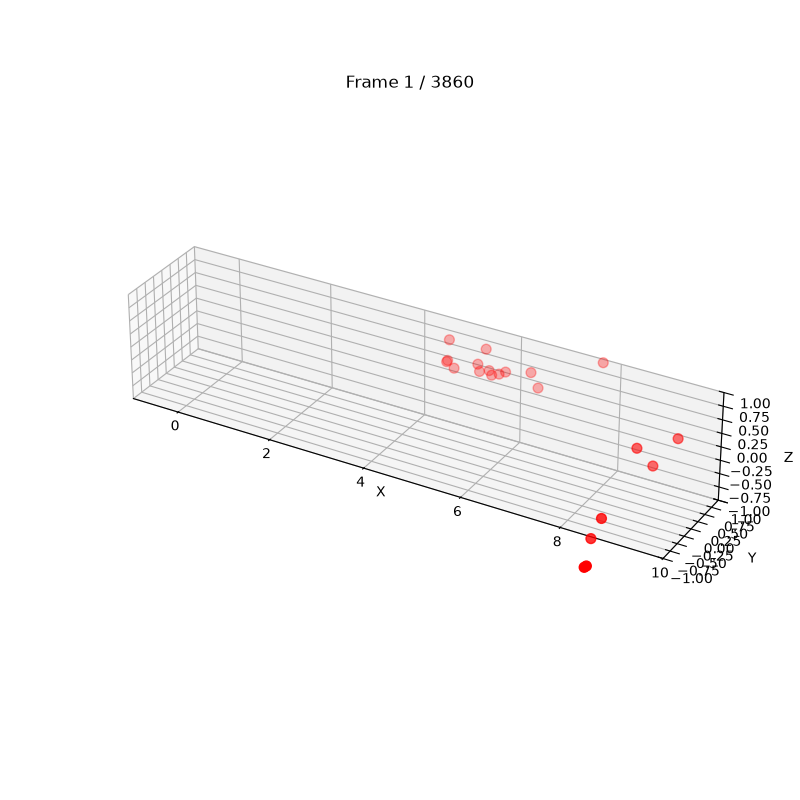

In [6]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib ipympl

frame = 0

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

keypoints = keypoints_3d


def update():
    ax.clear()

    pts = keypoints[frame]

    # Plot all 26 keypoints
    ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=50, c="red")

    ax.set_title(f"Frame {frame + 1} / {len(keypoints)}") 

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")

    ax.set_xlim(-1,10)
    ax.set_ylim(-1,1)
    ax.set_zlim(-1,1)
    
    ax.set_box_aspect([5, 1, 1])
    # ax.view_init(elev=10., azim=180)

    fig.canvas.draw_idle()


def on_key(event):
    global frame

    if event.key == "right":
        frame = min(frame + 1, len(keypoints) - 1)
        update()

    elif event.key == "left":
        frame = max(frame - 1, 0)
        update()
    elif event.key == "up":
        frame = min(frame + 30, len(keypoints) - 1)
        update()
    elif event.key == "down":
        frame = max(frame - 30, 0)
        update()

fig.canvas.mpl_connect("key_press_event", on_key)

update()
plt.show()

# Small tests

## Depth kernel

In [8]:
depth_frame = np.ones(shape=(10,15))
for i in range(depth_frame.shape[0]):
    for j in range(depth_frame.shape[1]):
        if j>4 and j<6:
            depth_frame[i][j]=5

depth_frame

array([[1., 1., 1., 1., 1., 5., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 5., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 5., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 5., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 5., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 5., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 5., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 5., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 5., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
       [1., 1., 1., 1., 1., 5., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])

In [ ]:


sample_depth_patch(depth_map=depth_frame, x=5, y=6, radius=1)

[[5. 1. 1.]
 [5. 1. 1.]
 [5. 1. 1.]]


[[1. 5. 1.]
 [1. 5. 1.]
 [1. 5. 1.]]


1.0

In [10]:
current_frame_depth_map.shape

(480, 848)

## Compressed depth

In [ ]:
import numpy as np
import blosc2

depth = np.asarray(depth_frame.get_data(), dtype=np.uint16)

compressed = blosc2.compress(
    depth,
    typesize=2,
    clevel=3,
    filter=blosc2.Filter.SHUFFLE,
    codec=blosc2.Codec.ZSTD
)

In [ ]:
raw = blosc2.decompress(compressed)

depth_restored = np.frombuffer(
    raw,
    dtype=np.uint16
).reshape(480, 848)

In [ ]:
assert np.array_equal(depth, depth_restored)

In [ ]:
import os
import json
import time
import struct

import cv2
import numpy as np
import pyrealsense2 as rs
import zstandard as zstd


recording_name = "asdf"

WIDTH = 848
HEIGHT = 480
FPS = 60
DURATION = 5

output_dir = os.path.join("data", recording_name)
os.makedirs(output_dir, exist_ok=True)

depth_filename = os.path.join(output_dir, "depth.zst")
color_filename = os.path.join(output_dir, "color.mp4")
timestamp_filename = os.path.join(output_dir, "timestamps.npz")
metadata_filename = os.path.join(output_dir, "metadata.json")

# REALSENSE SETUP
pipeline = rs.pipeline()
config = rs.config()

config.enable_stream(rs.stream.depth, WIDTH, HEIGHT, rs.format.z16, FPS)

config.enable_stream(rs.stream.color, WIDTH, HEIGHT, rs.format.bgr8, FPS)

queue = rs.frame_queue(capacity=30, keep_frames=True)


# CHECK CONFIGURATION
if not config.can_resolve(pipeline):
    raise RuntimeError(
        f"RealSense configuration cannot be resolved: " f"{WIDTH}x{HEIGHT} @ {FPS} FPS"
    )

print("Configuration OK")


# START CAMERA
profile = pipeline.start(config, queue)

device = profile.get_device()
depth_sensor = device.first_depth_sensor()
depth_scale = depth_sensor.get_depth_scale()

print("Depth scale:", depth_scale)


# COLOR VIDEO WRITER
# mp4v is widely available with OpenCV.
# It is LOSSY.
fourcc = cv2.VideoWriter_fourcc(*"mp4v")

video_writer = cv2.VideoWriter(color_filename, fourcc, FPS, (WIDTH, HEIGHT))
if not video_writer.isOpened():
    pipeline.stop()
    raise RuntimeError("Could not open color video writer")


# DEPTH COMPRESSOR
# Level 1 is deliberately fast.
# Increase to 3 or 5 if CPU usage/storage size permits.
compressor = zstd.ZstdCompressor(level=1)


# OPEN OUTPUT FILEs
depth_file = open(depth_filename, "wb")
timestamps = []
frame_numbers = []


start_time = time.perf_counter()
frame_count = 0

try:

    while time.perf_counter() - start_time < DURATION:

        frames = queue.wait_for_frame()
        frames = frames.as_frameset()

        depth_frame = frames.get_depth_frame()
        color_frame = frames.get_color_frame()

        if not depth_frame or not color_frame:
            continue

        depth_image = np.asanyarray(depth_frame.get_data())
        depth_image = np.asarray(depth_image, dtype=np.uint16)

        # Compress the complete depth frame.
        compressed_depth = compressor.compress(depth_image.tobytes())

        depth_file.write(struct.pack("<I", len(compressed_depth)))
        depth_file.write(compressed_depth)

        # COLOR        
        color_image = np.asanyarray(color_frame.get_data())
        video_writer.write(color_image)
        
        # TIMESTAMPS        
        timestamps.append(frames.get_timestamp())
        frame_numbers.append(frames.get_frame_number())

        frame_count += 1

        # OPTIONAL DISPLAY
        depth_colormap = cv2.applyColorMap(
            cv2.convertScaleAbs(depth_image, alpha=0.03), cv2.COLORMAP_JET
        )
        display = np.hstack((color_image, depth_colormap))
        cv2.imshow("RealSense", display)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

finally:
    depth_file.close()
    video_writer.release()

    cv2.destroyAllWindows()

    pipeline.stop()

# SAVE TIMESTAMPS

np.savez(
    timestamp_filename,
    timestamps=np.asarray(timestamps, dtype=np.float64),
    frame_numbers=np.asarray(frame_numbers, dtype=np.int64),
)

# SAVE METADATA

metadata = {
    "width": WIDTH,
    "height": HEIGHT,
    "fps": FPS,
    "frames": frame_count,
    "depth_format": "Z16",
    "depth_dtype": "uint16",
    "depth_compression": "zstd",
    "depth_compression_level": 1,
    "color_format": "BGR8",
    "color_container": "MP4",
    "color_codec": "mp4v",
    "depth_scale": depth_scale,
}

with open(metadata_filename, "w") as f:
    json.dump(metadata, f, indent=4)


print()
print("Recording finished")
print("Frames:", frame_count)
print("Expected:", FPS * DURATION)

print()
print("Files:")

for filename in [depth_filename, color_filename, timestamp_filename, metadata_filename]:
    size_mb = os.path.getsize(filename) / (1024**2)
    print(f"{filename}: {size_mb:.2f} MB")

## frame que test

In [ ]:
import pyrealsense2 as rs
import time

# Implement two "processing" functions, each of which
# occassionally lags and takes longer to process a frame.
def slow_processing(frame):
    n = frame.get_frame_number() 
    if n % 20 == 0:
        time.sleep(1/4)
    print(n)

def slower_processing(frame):
    n = frame.get_frame_number() 
    if n % 20 == 0:
        time.sleep(1)
    print(n)

def fast_processing(frame):
    n = frame.get_frame_number()
    print(n)

frame_numbers = {
    "fast": [],
    "slow": [],
    "slow_que": [],
    "slower": [],
    "slower_que": [],
}

try:

    pipeline = rs.pipeline()
    config = rs.config()
    config.enable_stream(rs.stream.depth, 640, 480, rs.format.z16, 30)
    config.enable_stream(rs.stream.color, 640, 480, rs.format.bgr8, 30)



    # FAST
    print('Fast callback')
    pipeline.start(config)
    start = time.time()
    while time.time() - start < 5:
        frames = pipeline.wait_for_frames()
        frame_numbers['fast'].append(frames.get_frame_number())
        fast_processing(frames)
    pipeline.stop()


    # SLOW
    # Start streaming to the slow processing function.
    # This stream will lag, causing the occasional frame drop.
    print("Slow callback")
    pipeline.start(config)
    start = time.time()
    while time.time() - start < 5:
        frames = pipeline.wait_for_frames()
        frame_numbers['slow'].append(frames.get_frame_number())
        slow_processing(frames)
    pipeline.stop()

    # SLOW + QUE
    # Start streaming to the the slow processing function by way of a frame queue.
    # This stream will occasionally hiccup, but the frame_queue will prevent frame loss.
    print("Slow callback + queue")
    queue = rs.frame_queue(50)
    pipeline.start(config, queue)
    start = time.time()
    while time.time() - start < 5:
        frames = queue.wait_for_frame()
        frame_numbers['slow_que'].append(frames.get_frame_number())
        slow_processing(frames)
    pipeline.stop()

    # SLOWER
    # Start streaming to the the slower processing function by way of a frame queue.
    # This stream will drop frames because the delays are long enough that the backed up
    # frames use the entire internal frame pool preventing the SDK from creating more frames.
    print("Slower callback + queue")
    queue = rs.frame_queue(50)
    pipeline.start(config, queue)
    start = time.time()
    while time.time() - start < 5:
        frames = queue.wait_for_frame()
        frame_numbers['slower'].append(frames.get_frame_number())
        slower_processing(frames)
    pipeline.stop()

    # SLOWER + QUE
    # Start streaming to the slower processing function by way of a keeping frame queue.
    # This stream will no longer drop frames because the frame queue tells the SDK
    # to remove the frames it holds from the internal frame queue, allowing the SDK to
    # allocate space for and create more frames .
    print("Slower callback + keeping queue")
    queue = rs.frame_queue(capacity=200, keep_frames=True)
    pipeline.start(config, queue)
    start = time.time()
    while time.time() - start < 5:
        frames = queue.wait_for_frame()
        frame_numbers['slower_que'].append(frames.get_frame_number())
        slower_processing(frames)
    pipeline.stop()

except Exception as e:
    print(e)
except:
    print("A different Error")
else:
    print("Done")

for key, value in frame_numbers.items():
    print(key, len(value))

In [ ]:
# type(frames)
frames.as_frameset()

In [ ]:
help(rs.composite_frame)

In [ ]:
for ind, frame in enumerate(frame_numbers['slower_que'],1):
    print(ind, frame)

In [ ]:
help(rs.frame_queue)

## Alignment test

In [ ]:
import matplotlib.pyplot as plt 

colorizer = rs.colorizer()
color = np.asanyarray(color_frame.get_data())

align = rs.align(align_to=rs.stream.color) # align_to=rs.stream.color/infra... -> aligns depth to other, align_to=RS2_STREAM_DEPTH -> align other stream to depth 
frameset = align.process(frames)

aligned_depth_frame = frameset.get_depth_frame()
colorized_depth = np.asanyarray(colorizer.colorize(aligned_depth_frame).get_data())

images = np.hstack((color, colorized_depth))
plt.imshow(images)

### Align while streaming/recording

In [ ]:
import os
import time
import pyrealsense2 as rs
import numpy as np
import cv2
import logging
import time

# config classes
pipeline = rs.pipeline()
config = rs.config()
file_name = 'align.db3'
out_file_name_color = os.path.splitext(file_name)[0] + 'color.avi'
out_file_name_infra = os.path.splitext(file_name)[0] + 'infra.avi'

recording_framerate = 60
width = 848
height = 480

# depth
config.enable_stream(
    stream_type=rs.stream.depth, width=width, height=height, format=rs.format.z16, framerate=recording_framerate
)
# color
config.enable_stream(
    stream_type=rs.stream.color, width=width, height=height, format=rs.format.bgr8, framerate=recording_framerate
)
# infra
config.enable_stream(
    stream_type=rs.stream.infrared, width=width, height=height, format=rs.format.bgr8, framerate=recording_framerate
)


# enable recording
config.enable_record_to_file(file_name=file_name)
queue = rs.frame_queue(capacity=2000, keep_frames=True)

# is selected config (for specific pipeline) valid
if config.can_resolve(pipeline):
    print('config OK')
else:
    print('baj van')

# opencv video writer
fourcc = cv2.VideoWriter_fourcc(*"XVID")
video_writer_color = cv2.VideoWriter(filename=out_file_name_color, fourcc=fourcc, fps=recording_framerate, frameSize=(width,height))
video_writer_infra = cv2.VideoWriter(filename=out_file_name_infra, fourcc=fourcc, fps=recording_framerate, frameSize=(width,height))



align_to = rs.stream.color
align = rs.align(align_to)

In [ ]:
# Start streaming
pipeline.start(config, queue)

start = time.time()
current_time = 0

frame_num = 0

depth_frames = np.empty(shape=(1,480,848))

try:
    while current_time-start < 65:

        # Wait for a coherent pair of frames: depth and color
        frames = queue.wait_for_frame()
        frames = frames.as_frameset()
        aligned_frames = align.process(frames)
   
        depth_frame = aligned_frames.get_depth_frame()
        color_frame = aligned_frames.get_color_frame()
        infra_frame = aligned_frames.get_infrared_frame()

        if not depth_frame or not color_frame or not infra_frame:
            continue

        # Convert images to numpy arrays
        depth_image = np.asanyarray(depth_frame.get_data())
        color_image = np.asanyarray(color_frame.get_data())
        infra_image = np.asanyarray(infra_frame.get_data())

        depth_frames = np.vstack((depth_frames,np.expand_dims(depth_image, axis=0)))

        # write color image (to video)
        video_writer_color.write(color_image)
        video_writer_infra.write(infra_image)
        frame_num+=1
        print(frame_num, color_frame.get_frame_number(), infra_frame.get_frame_number(), depth_frame.get_frame_number())

        # # Apply colormap on depth image (image must be converted to 8-bit per pixel first)
        # depth_colormap = cv2.applyColorMap(
        #     cv2.convertScaleAbs(depth_image, alpha=0.03), cv2.COLORMAP_JET
        # )

        # depth_colormap_dim = depth_colormap.shape
        # color_colormap_dim = color_image.shape

        # # If depth and color resolutions are different, resize color image to match depth image for display
        # if depth_colormap_dim != color_colormap_dim:
        #     resized_color_image = cv2.resize(
        #         color_image,
        #         dsize=(depth_colormap_dim[1], depth_colormap_dim[0]),
        #         interpolation=cv2.INTER_AREA,
        #     )
        #     images = np.hstack((resized_color_image, depth_colormap))
        # else:
        #     images = np.hstack((color_image, depth_colormap))
        #     # images = np.hstack((color_image, depth_colormap, infra_image))


        current_time=time.time()

        # Show images
        # cv2.namedWindow("RealSense", cv2.WINDOW_AUTOSIZE)
        # cv2.imshow("RealSense", images)

        # press q to exit without crash
    #     if cv2.waitKey(1) & 0xFF == ord("q"):
    #         break
    # cv2.destroyAllWindows()

finally:
    # stop video writer
    video_writer_color.release()
    video_writer_infra.release()

    # Stop streaming
    pipeline.stop()


In [ ]:
depth_frames

In [ ]:
d1 = depth_image
d2 = np.copy(depth_image)

asdf = np.stack([d1,d2])
asdf.shape

In [ ]:
d1.shape, np.expand_dims(d1,axis=0).shape, asdf.shape

In [ ]:
np.vstack((asdf,np.expand_dims(d1, axis=0)))

## check .db3 file

In [ ]:
import sqlite3


dbfile = './t1.db3'
# Create a SQL connection to our SQLite database
con = sqlite3.connect(dbfile)

# creating cursor
cur = con.cursor()

# reading all table names
# table_list = [a for a in cur.execute("SELECT name FROM sqlite_master WHERE type = 'table'")]
table_list = [a for a in cur.execute("SELECT name FROM sqlite_master WHERE type = 'table'")]
# here is you table list
print(table_list)

# Be sure to close the connection
con.close()

## Read depth file 

In [ ]:
import numpy as np

width = 848
height = 480

depth = np.memmap(
    "t1_depth_frames.raw",
    dtype=np.uint16,
    mode="r",
    shape=(height, width)
)

# Pixel at x=400, y=200
value = depth[200, 400]

print("Raw depth:", value)

In [ ]:
import numpy as np

width = 848
height = 480

bytes_per_frame = width * height * 2

frame_number = 100

with open("t1_depth_frames.raw", "rb") as f:
    f.seek(frame_number * bytes_per_frame)

    depth = np.fromfile(
        f,
        dtype=np.uint16,
        count=width * height
    ).reshape(height, width)

In [ ]:
import os

width = 848
height = 480
bytes_per_frame = width * height * 2  # uint16

size = os.path.getsize("t1_depth_frames.raw")
frames = size // bytes_per_frame

print("Depth frames:", frames)
print("File size:", size, "bytes")

if size % bytes_per_frame != 0:
    print("Warning: file size is not an exact multiple of one frame.")